In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint

In [ ]:
UNIVERSE = [
    "BTC",
    "ETH",
    "SOL",
    "BNB",
    "XRP",
    "DOGE",
    "ADA",
    "LINK",
    "AVAX",
    "DOT",
    "LTC",
    "ATOM",
    "AAVE",
    "UNI",
    "ARB",
    "OP",
    "SUI",
    "NEAR",
    "ALGO",
    "FIL"
]

In [3]:
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [ ]:
exchange = ccxt.kraken()
markets = exchange.load_markets()

symbols = []

for coin in UNIVERSE:
    c = f"{coin}/USD"
    if c in markets:
        symbols.append(c)

In [5]:
pairs = list(combinations(symbols, 2))

In [6]:
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close"]].copy()
    df = df.rename(columns={"close": symbol})
    return df

In [7]:
def align_pair_prices(prices, asset_a, asset_b):
    """
    prices: wide DataFrame with columns ['timestamp', asset_a, asset_b, ...]
    returns: DataFrame with only the two assets aligned and sorted
    """
    out = prices[["timestamp", asset_a, asset_b]].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [8]:
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Regress log(asset_a) on log(asset_b).
    Returns:
        df_out with log prices, spread, residuals
        alpha, beta, corr, pvalue
    """
    out = df.copy()

    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]

    model = sm.OLS(y, X).fit()

    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]

    out["spread"] = model.resid
    return out, alpha, beta, corr, model.pvalues[f"log_{asset_b}"]

In [9]:
def spread_half_life(spread):
    """
    Estimate half-life from AR(1)-style mean reversion.
    """
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag

    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]

    if len(tmp) < 5:
        return np.nan

    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]

    if lam >= 0:
        return np.nan

    return -np.log(2) / lam

In [10]:
def spread_crossings(z, threshold=2.0):
    """
    Count crossings of +/- threshold using one full-sample z-score series.
    """
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0

    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [11]:
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    """
    One-row summary for pair selection.
    """
    df, alpha, beta, corr, pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "P_value": pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread Vol": spread_vol,
        "Half_life": hl,
        "Z_score Crossings": crossings
    })

In [12]:
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [13]:
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25):
    """
    Stateful position series:
      +1 = long spread
      -1 = short spread
       0 = flat
    """
    position = 0
    positions = []

    for val in z:
        if pd.isna(val):
            positions.append(0)
            continue

        if position == 0:
            if val < -entry_z:
                position = 1
            elif val > entry_z:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0

        elif position == -1:
            if val < exit_z:
                position = 0

        positions.append(position)

    return pd.Series(positions, index=z.index)

In [14]:
def build_bollinger_positions(spread, window=25, band_k=1.0):
    """
    Stateful Bollinger-style spread strategy on the same spread.
    Enter on band break, exit when spread returns to rolling mean.
    """
    mid = spread.rolling(window).mean()
    std = spread.rolling(window).std()
    upper = mid + band_k * std
    lower = mid - band_k * std

    position = 0
    positions = []

    for s, m, u, l in zip(spread, mid, upper, lower):
        if pd.isna(s) or pd.isna(m) or pd.isna(u) or pd.isna(l):
            positions.append(0)
            continue

        if position == 0:
            if s < l:
                position = 1
            elif s > u:
                position = -1

        elif position == 1:
            if s >= m:
                position = 0

        elif position == -1:
            if s <= m:
                position = 0

        positions.append(position)

    out = pd.Series(positions, index=spread.index)
    return out, mid, upper, lower

In [15]:
def backtest_pair_strategy(
    prices,
    asset_a,
    asset_b,
    strategy="zscore",
    beta=None,
    window=25,
    entry_z=2.0,
    exit_z=0.25,
    band_k=1.0,
    fee_bps=0.0
):
    """
    prices: wide DataFrame with timestamp, asset_a, asset_b
    strategy: 'zscore' or 'bollinger'

    Returns:
        bt_df: full backtest DataFrame
        metrics: one-row summary Series
    """
    df = align_pair_prices(prices, asset_a, asset_b)
    df, alpha_hat, beta_hat, corr, pvalue = estimate_ols_spread(df, asset_a, asset_b)

    if beta is None:
        beta = beta_hat

    # Core spread
    df["spread"] = df["spread"]
    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    if strategy == "zscore":
        df["zscore"] = rolling_zscore(df["spread"], window=window)
        df["position"] = build_zscore_positions(
            df["zscore"], entry_z=entry_z, exit_z=exit_z
        )

    elif strategy == "bollinger":
        df["position"], df["bb_mid"], df["bb_upper"], df["bb_lower"] = build_bollinger_positions(
            df["spread"], window=window, band_k=band_k
        )

    else:
        raise ValueError("strategy must be 'zscore' or 'bollinger'")

    # Legs
    # position = +1 long spread => long A, short beta * B
    # position = -1 short spread => short A, long beta * B
    # df["w_a"] = df["position"].astype(float)
    # df["w_b"] = -beta * df["position"].astype(float)

    gross = 1 + abs(beta)

    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    # Returns
    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    # Strategy return, shifted to avoid look-ahead
    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )

    # Optional transaction costs on turnover
    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )

    cost_per_turn = fee_bps / 10000.0
    costs = turnover * cost_per_turn

    df["strategy_ret"] = raw_ret - costs
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    # Metrics
    r = df["strategy_ret"].dropna()
    ann_factor = np.sqrt(24 * 365)

    sharpe = (r.mean() / r.std()) * ann_factor if r.std() != 0 else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1
    trades = (df["position"].diff().fillna(0) != 0).sum()

    # print(turnover.describe())

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Strategy": strategy,
        "Corr": corr,
        "P-value": pvalue,
        "Alpha": alpha_hat,
        "Beta": beta,
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Trades": int(trades),
        "Mean Hourly Return": r.mean(),
        "Vol Hourly": r.std()
    })

    return df, metrics

In [16]:
def build_equal_vol_portfolio(ret_list):
    rets = pd.concat(ret_list, axis=1, join="inner").dropna()

    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()

    port_ret = rets.mul(weights, axis=1).sum(axis=1)
    port_eq = (1 + port_ret.fillna(0)).cumprod()

    sharpe = (port_ret.mean() / port_ret.std()) * np.sqrt(24 * 365) if port_ret.std() != 0 else np.nan
    max_dd = (port_eq / port_eq.cummax() - 1).min()
    cum_ret = port_eq.iloc[-1] - 1

    summary = pd.Series({
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Mean Hourly Return": port_ret.mean(),
        "Vol Hourly": port_ret.std(),
        "N Strategies": rets.shape[1]
    })

    return port_ret, port_eq, weights, summary

In [17]:
prices = None

for coin in UNIVERSE:
    data = exchange.fetch_ohlcv(f"{coin}/USD", timeframe="1h", limit=1000)
    df = to_df(data, coin)

    if prices is None:
        prices = df
    else:
        prices = prices.merge(df, on="timestamp", how="inner")

In [18]:
candidate_rows = []

for a, b in pairs:
    candidate_rows.append(pair_summary(prices, a.split("/")[0], b.split("/")[0]))

pair_table = pd.DataFrame(candidate_rows).sort_values("P_value")

result = pair_table.query('Corr > 0.8')
result = result.query('P_value < 0.05')
result = result.sort_values(by="Half_life")
result = result.sort_values(by="Z_score Crossings", ascending=False)

selected_pairs = result.reset_index().drop(columns=["index"])

In [19]:
get_A = lambda x : x.split("/")[0]
get_B = lambda x : x.split("/")[1]

selected_pairs["Asset_A"] = selected_pairs["Pair"].apply(get_A)
selected_pairs["Asset_B"] = selected_pairs["Pair"].apply(get_B)

In [20]:
selected_pairs.head()

,Pair,Asset_A,Asset_B,Corr,P_value,Alpha,Beta,Spread Vol,Half_life,Z_score Crossings
0,DOGE/DOT,DOGE,DOT,0.937174,0.000000e+00,-2.455203,0.896322,0.015589,24.645767,17
1,BNB/NEAR,BNB,NEAR,0.808192,1.719011e-167,6.126997,0.328481,0.012280,21.233479,10
2,XRP/NEAR,XRP,NEAR,0.835029,9.748169e-189,-0.253080,0.513834,0.017370,26.648275,10
3,DOGE/ATOM,DOGE,ATOM,0.930951,0.000000e+00,-2.965487,0.810184,0.016316,19.620232,10
4,UNI/ARB,UNI,ARB,0.859746,5.285198e-212,3.587071,0.970156,0.047011,37.783261,9


In [21]:
all_backtests = {}
all_results = []
z_returns = []
bb_returns = []

for _, row in selected_pairs.iterrows():
    a = row["Asset_A"]
    b = row["Asset_B"]

    bt_z, m_z = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="zscore",
        beta=row.get("Beta", None),
        window=25,
        entry_z=2.0,
        exit_z=0.25,
        fee_bps=7.0
    )

    bt_bb, m_bb = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="bollinger",
        beta=row.get("Beta", None),
        window=25,
        band_k=1.0,
        fee_bps=7.0
    )

    all_backtests[(a, b, "zscore")] = bt_z
    all_backtests[(a, b, "bollinger")] = bt_bb

    z_returns.append(bt_z["strategy_ret"].rename(f"{a}/{b}"))
    bb_returns.append(bt_bb["strategy_ret"].rename(f"{a}/{b}"))


    all_results.append(m_z)
    all_results.append(m_bb)
    
results_df = pd.DataFrame(all_results).sort_values(["Pair", "Strategy"])
results_df = results_df.set_index(["Pair", "Strategy"]).sort_index()
results_df.head()

Corr        P-value     Alpha      Beta    Sharpe  \
Pair      Strategy                                                           
ADA/SUI   bollinger  0.827270  3.215041e-182 -1.241421  1.794160  3.591826   
          zscore     0.827270  3.215041e-182 -1.241421  1.794160  3.209992   
ATOM/ALGO bollinger  0.824748  3.596608e-180  3.177460  1.108582 -0.517923   
          zscore     0.824748  3.596608e-180  3.177460  1.108582 -1.212009   
BNB/FIL   bollinger  0.825712  5.976910e-181  6.475006  0.483291  0.723819   

                     Cumulative Return  Max Drawdown  Trades  \
Pair      Strategy                                             
ADA/SUI   bollinger           0.072138     -0.045418      93   
          zscore              0.050438     -0.033380      49   
ATOM/ALGO bollinger          -0.013503     -0.084556      93   
          zscore             -0.023454     -0.072395      43   
BNB/FIL   bollinger           0.008148     -0.027936      91   

                     Mean Hourly Return  Vol Hourly  
Pair      Strategy                                   
ADA/SUI   bollinger            0.000100    0.002610  
          zscore               0.000070    0.002054  
ATOM/ALGO bollinger           -0.000015    0.002736  
          zscore              -0.000030    0.002335  
BNB/FIL   bollinger            0.000013    0.001629

In [22]:
z_port_ret, z_port_eq, z_weights, z_summary = build_equal_vol_portfolio(z_returns)
bb_port_ret, bb_port_eq, bb_weights, bb_summary = build_equal_vol_portfolio(bb_returns)

In [23]:
portfolio_results_df = pd.DataFrame({
    "zscore": z_summary,
    "bollinger": bb_summary
}).T

portfolio_results_df

,Sharpe,Cumulative Return,Max Drawdown,Mean Hourly Return,Vol Hourly,N Strategies
zscore,3.885572,0.011960,-0.004457,0.000017,0.000400,28.0
bollinger,0.699218,0.002689,-0.010623,0.000004,0.000517,28.0


In [24]:
wide = results_df.unstack("Strategy")

In [25]:
comparison = wide[[
    ("Sharpe", "zscore"),
    ("Sharpe", "bollinger"),
    ("Cumulative Return", "zscore"),
    ("Cumulative Return", "bollinger"),
    ("Max Drawdown", "zscore"),
    ("Max Drawdown", "bollinger"),
]].copy()

comparison.columns = [
    "Sharpe_Z",
    "Sharpe_BB",
    "Return_Z",
    "Return_BB",
    "DD_Z",
    "DD_BB",
]
comparison["Sharpe_diff"] = comparison["Sharpe_Z"] - comparison["Sharpe_BB"]
comparison["Return_diff"] = comparison["Return_Z"] - comparison["Return_BB"]
comparison["DD_diff"] = comparison["DD_Z"] - comparison["DD_BB"]

In [26]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/SUI,3.209992,3.591826,0.050438,0.072138,-0.033380,-0.045418,-0.381834,-0.021700,0.012038
ATOM/ALGO,-1.212009,-0.517923,-0.023454,-0.013503,-0.072395,-0.084556,-0.694085,-0.009951,0.012161
BNB/FIL,3.393220,0.723819,0.033038,0.008148,-0.022593,-0.027936,2.669402,0.024890,0.005343
BNB/NEAR,3.056350,1.199885,0.034125,0.016484,-0.028981,-0.033050,1.856465,0.017641,0.004069
BNB/XRP,1.804649,0.766525,0.012755,0.006915,-0.016537,-0.024461,1.038125,0.005840,0.007924


In [27]:
z_count = 0
b_count = 0

for _, row in comparison.iterrows():
    if row["Sharpe_diff"] > 0:
        z_count += 1
    else:
        b_count += 1


In [28]:
print(z_count > b_count)

True


In [29]:
bb_summary = results_df.xs('bollinger', level='Strategy')
z_summary = results_df.xs('zscore', level='Strategy')


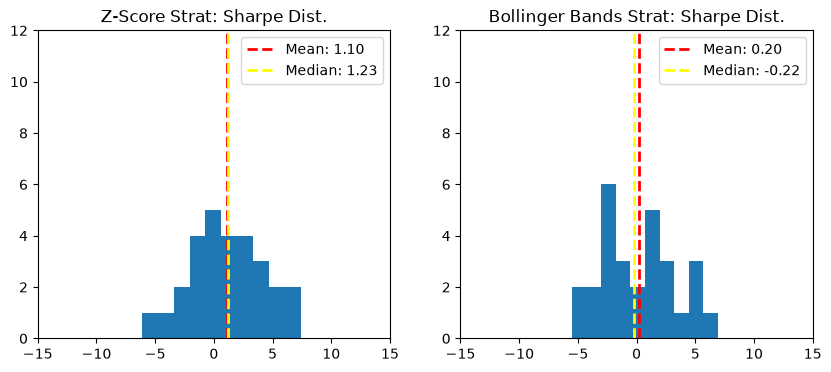

In [30]:
fig1, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].hist(z_summary[["Sharpe"]])
zscore_mean = np.mean(z_summary[["Sharpe"]])
ax[0].axvline(zscore_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {zscore_mean:.2f}')
zscore_median = np.median(z_summary[["Sharpe"]])
ax[0].axvline(zscore_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {zscore_median:.2f}')

ax[1].hist(bb_summary[["Sharpe"]])
bb_mean = np.mean(bb_summary[["Sharpe"]])
ax[1].axvline(bb_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {bb_mean:.2f}')
bb_median = np.median(bb_summary[["Sharpe"]])
ax[1].axvline(bb_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {bb_median:.2f}')

ax[0].set_title("Z-Score Strat: Sharpe Dist.")
ax[1].set_title("Bollinger Bands Strat: Sharpe Dist.")

ax[0].set_xlim(-15, 15)
ax[0].set_ylim(0, 12)
ax[1].set_xlim(-15, 15)
ax[1].set_ylim(0, 12)

ax[0].legend()
ax[1].legend()

In [31]:
results_df.index.get_level_values("Strategy").unique()

Index(['bollinger', 'zscore'], dtype='str', name='Strategy')

In [32]:
color_map = {'zscore': 'yellow', 'bollinger': 'red'}
colors = [color_map[cat] for cat in results_df.index.get_level_values("Strategy")]

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_79532/759719422.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Risk to Return Comparison')

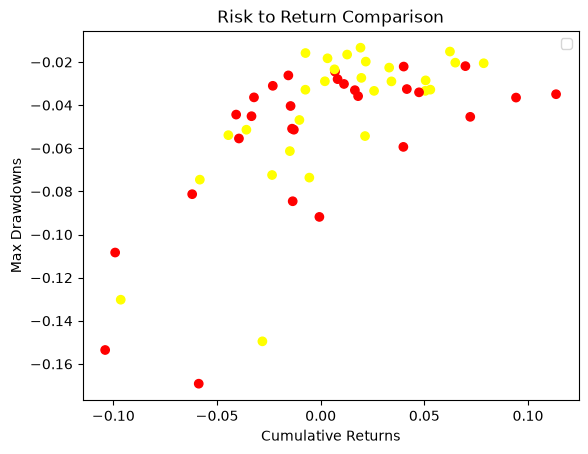

In [33]:
plt.scatter(results_df[["Cumulative Return"]].values, results_df[["Max Drawdown"]].values, c=colors)
plt.xlabel("Cumulative Returns")
plt.ylabel("Max Drawdowns")
plt.legend()
plt.title("Risk to Return Comparison")

Text(0.5, 0.98, 'Distribution of Metrics Differences')

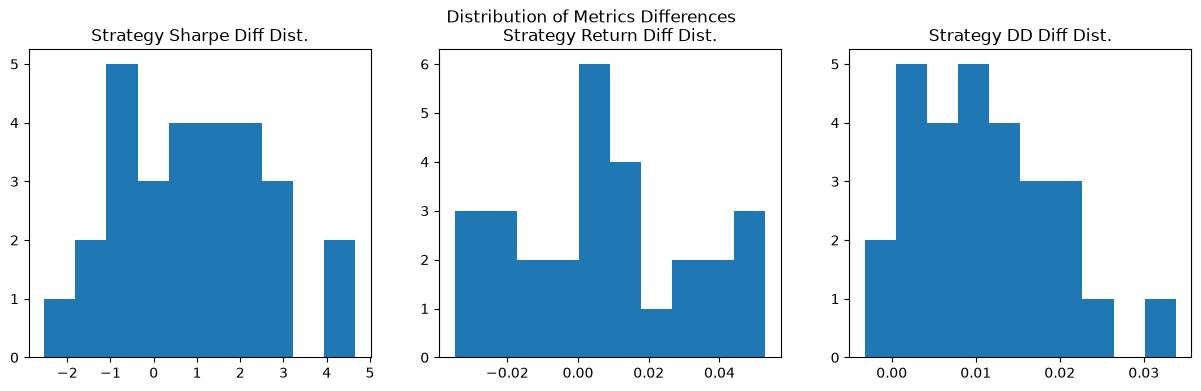

In [34]:
fig3, ax3 = plt.subplots(1, 3, figsize=(15, 4))

ax3[0].hist(comparison[["Sharpe_diff"]])
ax3[1].hist(comparison[["Return_diff"]])
ax3[2].hist(comparison[["DD_diff"]])

ax3[0].set_title("Strategy Sharpe Diff Dist.")
ax3[1].set_title("Strategy Return Diff Dist.")
ax3[2].set_title("Strategy DD Diff Dist.")

fig3.suptitle("Distribution of Metrics Differences")

Text(0.5, 0.98, 'Performance Metrics Comparison')

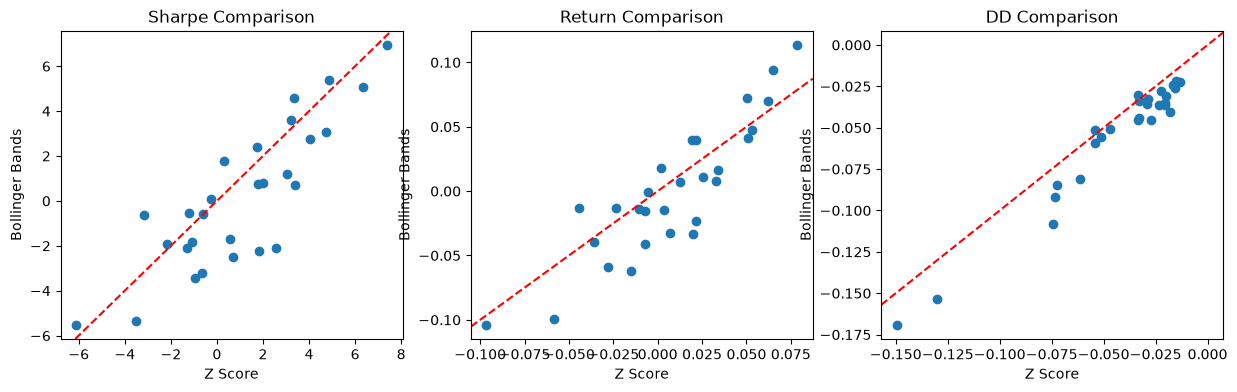

In [35]:
fig4, ax4 = plt.subplots(1, 3, figsize=(15, 4))

ax4[0].scatter(comparison[["Sharpe_Z"]], comparison[["Sharpe_BB"]])
ax4[1].scatter(comparison[["Return_Z"]], comparison[["Return_BB"]])
ax4[2].scatter(comparison[["DD_Z"]], comparison[["DD_BB"]])

ax4[0].set_title("Sharpe Comparison")
ax4[1].set_title("Return Comparison")
ax4[2].set_title("DD Comparison")

ax4[0].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[1].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[2].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")

ax4[0].set_xlabel("Z Score")
ax4[1].set_xlabel("Z Score")
ax4[2].set_xlabel("Z Score")

ax4[0].set_ylabel("Bollinger Bands")
ax4[1].set_ylabel("Bollinger Bands")
ax4[2].set_ylabel("Bollinger Bands")

fig3.suptitle("Performance Metrics Comparison")

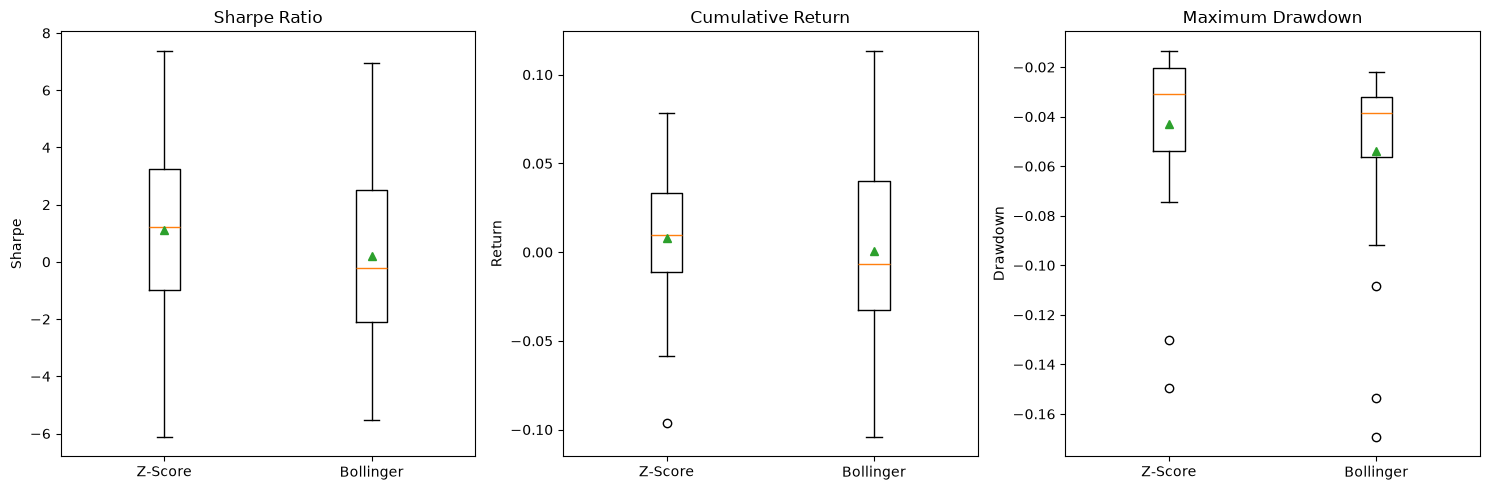

In [36]:
fig5, ax5 = plt.subplots(1, 3, figsize=(15, 5))

# -----------------------
# Sharpe
# -----------------------
ax5[0].boxplot(
    [comparison["Sharpe_Z"], comparison["Sharpe_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[0].set_title("Sharpe Ratio")
ax5[0].set_ylabel("Sharpe")

# -----------------------
# Cumulative Return
# -----------------------
ax5[1].boxplot(
    [comparison["Return_Z"], comparison["Return_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[1].set_title("Cumulative Return")
ax5[1].set_ylabel("Return")

# -----------------------
# Max Drawdown
# -----------------------
ax5[2].boxplot(
    [comparison["DD_Z"], comparison["DD_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[2].set_title("Maximum Drawdown")
ax5[2].set_ylabel("Drawdown")

plt.tight_layout()
plt.show()

In [37]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/SUI,3.209992,3.591826,0.050438,0.072138,-0.033380,-0.045418,-0.381834,-0.021700,0.012038
ATOM/ALGO,-1.212009,-0.517923,-0.023454,-0.013503,-0.072395,-0.084556,-0.694085,-0.009951,0.012161
BNB/FIL,3.393220,0.723819,0.033038,0.008148,-0.022593,-0.027936,2.669402,0.024890,0.005343
BNB/NEAR,3.056350,1.199885,0.034125,0.016484,-0.028981,-0.033050,1.856465,0.017641,0.004069
BNB/XRP,1.804649,0.766525,0.012755,0.006915,-0.016537,-0.024461,1.038125,0.005840,0.007924


In [38]:
from scipy.stats import ttest_rel
ttest_rel(comparison["Sharpe_Z"], comparison["Sharpe_BB"])

TtestResult(statistic=np.float64(2.799085823628651), pvalue=np.float64(0.009345216361961756), df=np.int64(27))

In [39]:
ttest_rel(comparison["Return_Z"], comparison["Return_BB"])


TtestResult(statistic=np.float64(1.5863820920963037), pvalue=np.float64(0.1242963647771609), df=np.int64(27))

In [40]:
ttest_rel(comparison["DD_Z"], comparison["DD_BB"])

TtestResult(statistic=np.float64(6.970649445789413), pvalue=np.float64(1.7153844976877766e-07), df=np.int64(27))

In [41]:
results_df.sort_values(by="Sharpe", ascending=False)

Corr        P-value     Alpha      Beta    Sharpe  \
Pair      Strategy                                                           
SOL/SUI   zscore     0.814584  3.103214e-172  4.736457  1.269681  7.383251   
          bollinger  0.814584  3.103214e-172  4.736457  1.269681  6.945268   
LINK/SUI  zscore     0.840452  1.691921e-193  2.424667  1.138212  6.326683   
ETH/SUI   bollinger  0.843844  1.443212e-196  7.922934  1.441136  5.366976   
LINK/SUI  bollinger  0.840452  1.691921e-193  2.424667  1.138212  5.082446   
ETH/SUI   zscore     0.843844  1.443212e-196  7.922934  1.441136  4.848329   
XRP/FIL   zscore     0.882887  3.091413e-238  0.298325  0.782367  4.731461   
BTC/LINK  bollinger  0.926202  8.299341e-307  9.870255  0.570590  4.571809   
DOGE/ATOM zscore     0.930951   0.000000e+00 -2.965487  0.810184  4.034600   
ADA/SUI   bollinger  0.827270  3.215041e-182 -1.241421  1.794160  3.591826   
BNB/FIL   zscore     0.825712  5.976910e-181  6.475006  0.483291  3.393220   
BTC/LINK  zscore     0.926202  8.299341e-307  9.870255  0.570590  3.359891   
ADA/SUI   zscore     0.827270  3.215041e-182 -1.241421  1.794160  3.209992   
BNB/NEAR  zscore     0.808192  1.719011e-167  6.126997  0.328481  3.056350   
XRP/FIL   bollinger  0.882887  3.091413e-238  0.298325  0.782367  3.055373   
DOGE/ATOM bollinger  0.930951   0.000000e+00 -2.965487  0.810184  2.760361   
BTC/LTC   zscore     0.844240  6.249217e-197  8.259574  0.736074  2.551268   
XRP/NEAR  bollinger  0.835029  9.748169e-189 -0.253080  0.513834  2.406908   
XRP/ADA   zscore     0.800985  2.368721e-162  0.699058  0.333722  2.012418   
ETH/LTC   zscore     0.861143  1.892992e-213  1.643509  1.536897  1.812777   
BNB/XRP   zscore     0.862267  1.264865e-214  6.295055  0.569529  1.804649   
BTC/ETH   bollinger  0.913282  1.156601e-282  7.716742  0.446160  1.794242   
XRP/NEAR  zscore     0.835029  9.748169e-189 -0.253080  0.513834  1.747612   
BNB/NEAR  bollinger  0.808192  1.719011e-167  6.126997  0.328481  1.199885   
XRP/ADA   bollinger  0.800985  2.368721e-162  0.699058  0.333722  0.812938   
BNB/XRP   bollinger  0.862267  1.264865e-214  6.295055  0.569529  0.766525   
BNB/FIL   bollinger  0.825712  5.976910e-181  6.475006  0.483291  0.723819   
DOGE/DOT  zscore     0.937174   0.000000e+00 -2.455203  0.896322  0.718501   
ETH/LINK  zscore     0.976140   0.000000e+00  4.925229  1.230962  0.561254   
BTC/ETH   zscore     0.913282  1.156601e-282  7.716742  0.446160  0.295376   
DOGE/ALGO bollinger  0.866890  1.434347e-219 -0.107533  1.014067  0.079527   
          zscore     0.866890  1.434347e-219 -0.107533  1.014067 -0.271269   
ATOM/ALGO bollinger  0.824748  3.596608e-180  3.177460  1.108582 -0.517923   
LINK/UNI  zscore     0.827103  4.409440e-182  1.559476  0.425164 -0.591958   
          bollinger  0.827103  4.409440e-182  1.559476  0.425164 -0.605575   
LINK/LTC  zscore     0.886858  2.703435e-243 -2.690942  1.255136 -0.629603   
SOL/AVAX  bollinger  0.829128  9.470710e-184  1.928374  1.274860 -0.640007   
ETH/UNI   zscore     0.887166  1.072990e-243  6.784690  0.575089 -0.935624   
UNI/ARB   zscore     0.859746  5.285198e-212  3.587071  0.970156 -1.097690   
ATOM/ALGO zscore     0.824748  3.596608e-180  3.177460  1.108582 -1.212009   
BTC/BNB   zscore     0.839042  3.041233e-192  3.598790  1.172910 -1.290136   
ETH/LINK  bollinger  0.976140   0.000000e+00  4.925229  1.230962 -1.680932   
UNI/ARB   bollinger  0.859746  5.285198e-212  3.587071  0.970156 -1.848592   
DOT/ATOM  bollinger  0.884975  7.134281e-241 -0.523465  0.805274 -1.927696   
BTC/BNB   bollinger  0.839042  3.041233e-192  3.598790  1.172910 -2.086506   
BTC/LTC   bollinger  0.844240  6.249217e-197  8.259574  0.736074 -2.104472   
DOT/ATOM  zscore     0.884975  7.134281e-241 -0.523465  0.805274 -2.153740   
ETH/LTC   bollinger  0.861143  1.892992e-213  1.643509  1.536897 -2.242412   
DOGE/DOT  bollinger  0.937174   0.000000e+00 -2.455203  0.896322 -2.483152   
SOL/AVAX  zscore     0.829128  9.470710e-184  1

In [42]:
results_df.sort_values(by="Cumulative Return", ascending=False)

,,Corr,P-value,Alpha,Beta,Sharpe,Cumulative Return,Max Drawdown,Trades,Mean Hourly Return,Vol Hourly
Pair,Strategy,,,,,,,,,,
SOL/SUI,bollinger,0.814584,3.103214e-172,4.736457,1.269681,6.945268,0.113531,-0.034924,109,0.000151,0.002041
ETH/SUI,bollinger,0.843844,1.443212e-196,7.922934,1.441136,5.366976,0.094224,-0.036490,81,0.000128,0.002224
SOL/SUI,zscore,0.814584,3.103214e-172,4.736457,1.269681,7.383251,0.078619,-0.020570,46,0.000106,0.001344
ADA/SUI,bollinger,0.827270,3.215041e-182,-1.241421,1.794160,3.591826,0.072138,-0.045418,93,0.000100,0.002610
LINK/SUI,bollinger,0.840452,1.691921e-193,2.424667,1.138212,5.082446,0.069794,-0.021901,87,0.000095,0.001754
ETH/SUI,zscore,0.843844,1.443212e-196,7.922934,1.441136,4.848329,0.064924,-0.020296,52,0.000089,0.001715
LINK/SUI,zscore,0.840452,1.691921e-193,2.424667,1.138212,6.326683,0.062347,-0.015142,49,0.000085,0.001254
XRP/FIL,zscore,0.882887,3.091413e-238,0.298325,0.782367,4.731461,0.052884,-0.032808,45,0.000073,0.001436
DOGE/ATOM,zscore,0.930951,0.000000e+00,-2.965487,0.810184,4.034600,0.050616,-0.028509,53,0.000070,0.001621


Text(0.5, 1.0, 'Equal Volatility Portfolio')

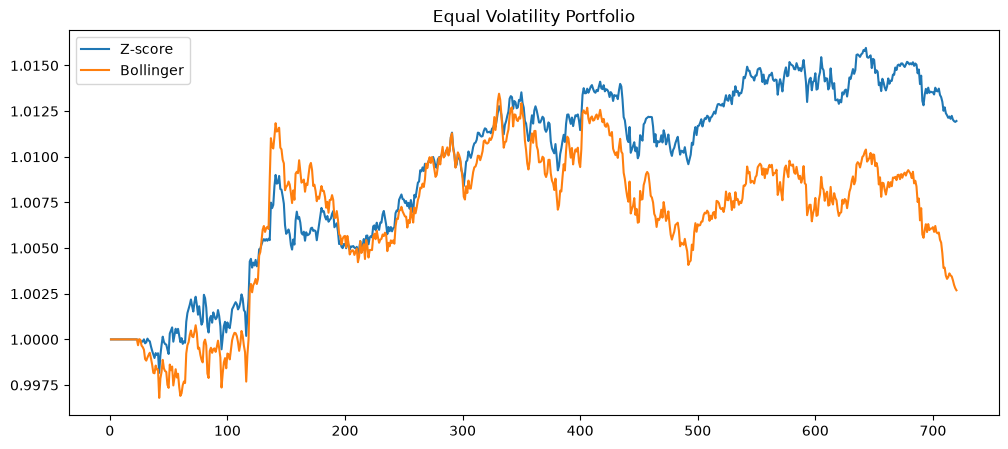

In [43]:
plt.figure(figsize=(12,5))
plt.plot(z_port_eq, label="Z-score")
plt.plot(bb_port_eq, label="Bollinger")
plt.legend()
plt.title("Equal Volatility Portfolio")

In [44]:
z_drawdown = z_port_eq / z_port_eq.cummax() - 1
bb_drawdown = bb_port_eq / bb_port_eq.cummax() - 1

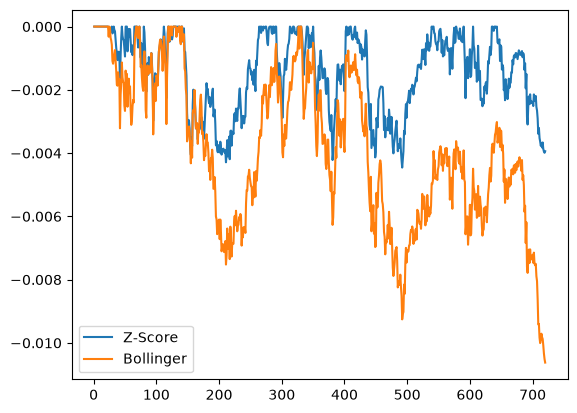

In [45]:
plt.plot(z_drawdown, label='Z-Score')
plt.plot(bb_drawdown, label="Bollinger")
plt.legend()

In [46]:
ann_factor = np.sqrt(24 * 365)

expanding_sharpe_z = (
    z_port_ret.expanding(min_periods=100).mean() /
    z_port_ret.expanding(min_periods=100).std()
) * ann_factor

expanding_sharpe_bb = (
    bb_port_ret.expanding(min_periods=100).mean() /
    bb_port_ret.expanding(min_periods=100).std()
) * ann_factor

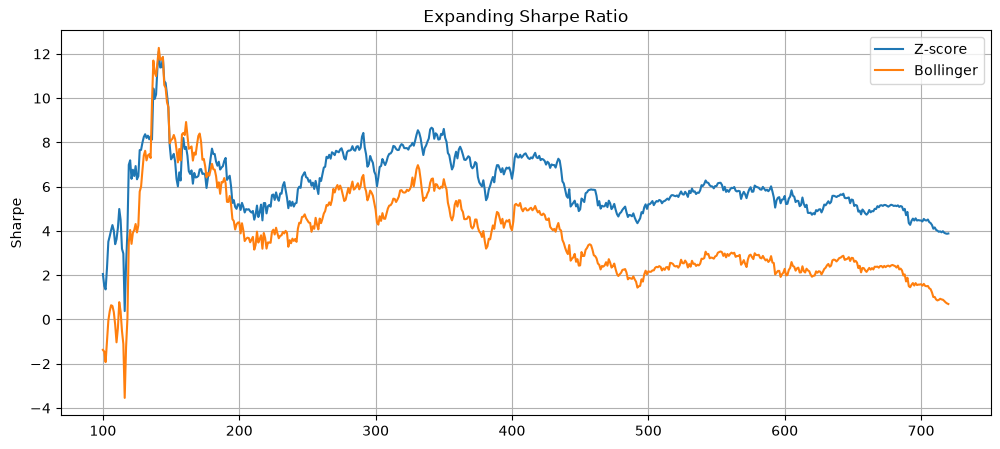

In [47]:
plt.figure(figsize=(12,5))
plt.plot(expanding_sharpe_z, label="Z-score")
plt.plot(expanding_sharpe_bb, label="Bollinger")
plt.title("Expanding Sharpe Ratio")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True)

In [48]:
expanding_vol_z = (
    z_port_ret.expanding(min_periods=100).std()
) * ann_factor

expanding_vol_bb = (
    bb_port_ret.expanding(min_periods=100).std()
) * ann_factor

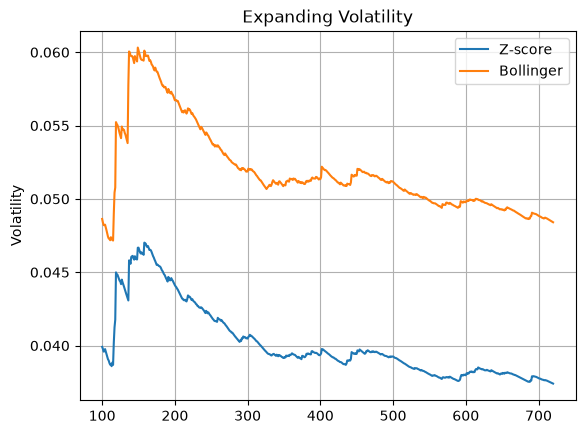

In [49]:
plt.plot(expanding_vol_z, label="Z-score")
plt.plot(expanding_vol_bb, label="Bollinger")
plt.title("Expanding Volatility")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)

In [50]:
rolling_vol_z = (
    z_port_ret.rolling(24).std())

rolling_vol_bb = (
    bb_port_ret.rolling(24).std())

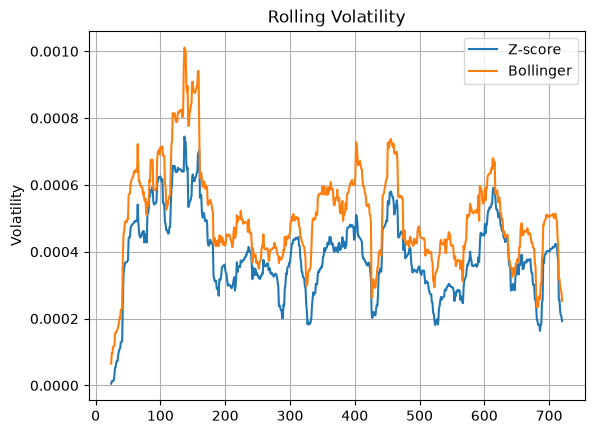

In [51]:
plt.plot(rolling_vol_z, label="Z-score")
plt.plot(rolling_vol_bb, label="Bollinger")
plt.title("Rolling Volatility")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)

(array([ 3.,  2.,  1.,  2.,  1.,  0.,  2.,  5.,  4., 13., 10., 13., 24.,
        26., 33., 44., 45., 40., 48., 77., 47., 66., 47., 45., 34., 11.,
        15., 14., 17.,  8.,  5.,  5.,  2.,  2.,  0.,  2.,  1.,  1.,  1.,
         0.,  0.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  1.,  1.]),
 array([-1.73053613e-03, -1.64161795e-03, -1.55269977e-03, -1.46378159e-03,
        -1.37486341e-03, -1.28594523e-03, -1.19702704e-03, -1.10810886e-03,
        -1.01919068e-03, -9.30272504e-04, -8.41354324e-04, -7.52436144e-04,
        -6.63517964e-04, -5.74599784e-04, -4.85681604e-04, -3.96763424e-04,
        -3.07845243e-04, -2.18927063e-04, -1.30008883e-04, -4.10907030e-05,
         4.78274772e-05,  1.36745657e-04,  2.25663838e-04,  3.14582018e-04,
         4.03500198e-04,  4.92418378e-04,  5.81336558e-04,  6.70254738e-04,
         7.59172918e-04,  8.48091099e-04,  9.37009279e-04,  1.02592746e-03,
         1.11484564e-03,  1.20376382e-03,  1.29268200e-03,  1.38160018e-03,
         1.47051836e-03,  1.5594

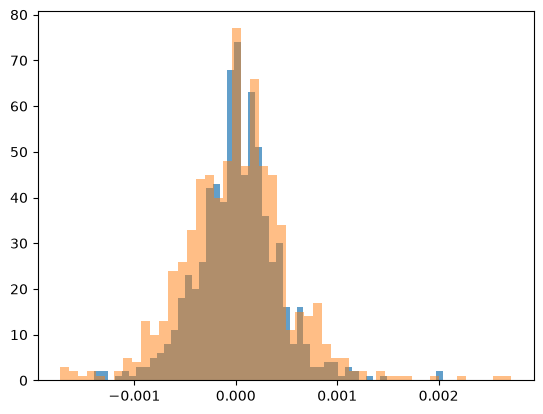

In [52]:
plt.hist(z_port_ret, bins=50, alpha=.7)
plt.hist(bb_port_ret, bins=50, alpha=.5)

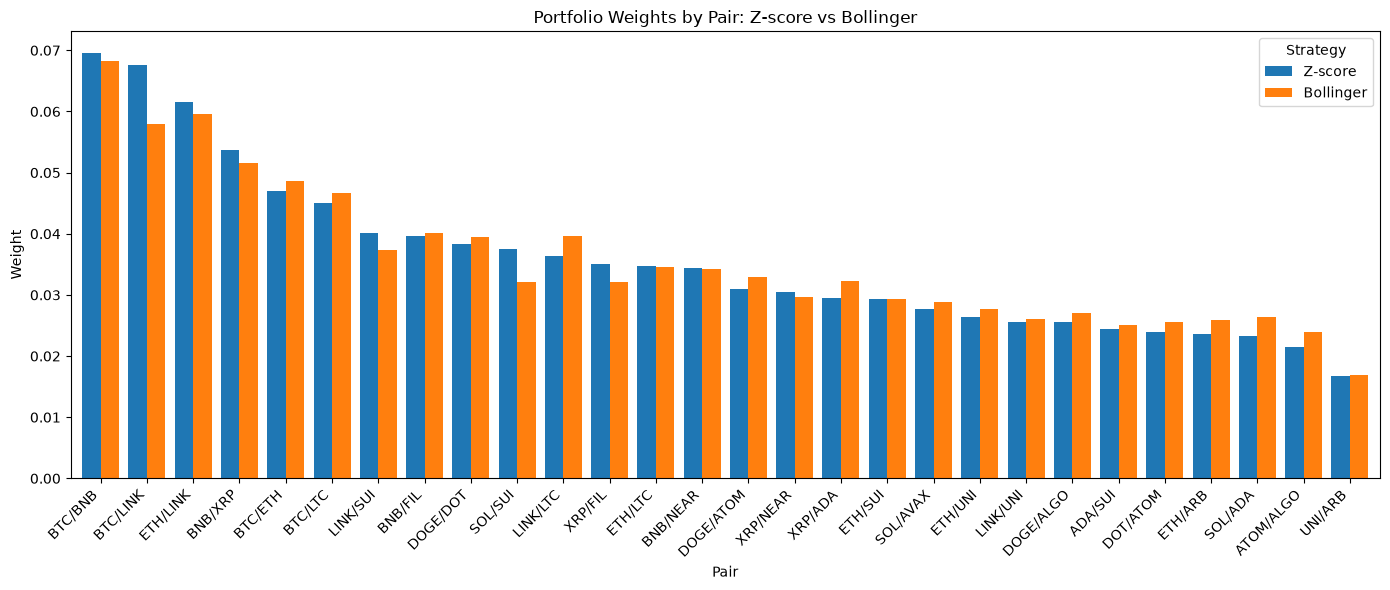

In [53]:
weights_df = pd.concat(
    [z_weights.rename("Z-score"), bb_weights.rename("Bollinger")],
    axis=1
).fillna(0)

# Optional: sort by one of the strategies or by average weight
weights_df = weights_df.sort_values(by="Z-score", ascending=False)

# Plot side-by-side bars
ax = weights_df.plot(kind="bar", figsize=(14, 6), width=0.8)

ax.set_title("Portfolio Weights by Pair: Z-score vs Bollinger")
ax.set_xlabel("Pair")
ax.set_ylabel("Weight")
ax.legend(title="Strategy")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [65]:
z_ret_dict = {}
bb_ret_dict = {}

for (a, b, strat), bt in all_backtests.items():
    pair_name = f"{a}/{b}"
    if strat == "zscore":
        z_ret_dict[pair_name] = bt["strategy_ret"]
    elif strat == "bollinger":
        bb_ret_dict[pair_name] = bt["strategy_ret"]

z_rets = pd.concat(z_ret_dict, axis=1)
bb_rets = pd.concat(bb_ret_dict, axis=1)

In [74]:
z_contrib = z_rets.mul(z_weights, axis=1)
bb_contrib = bb_rets.mul(bb_weights, axis=1)

In [76]:
z_pair_contrib = z_contrib.sum()
bb_pair_contrib = bb_contrib.sum()

In [78]:
pair_contrib_df = pd.concat(
    [z_pair_contrib.rename("Z-score"), bb_pair_contrib.rename("Bollinger")],
    axis=1
).fillna(0)

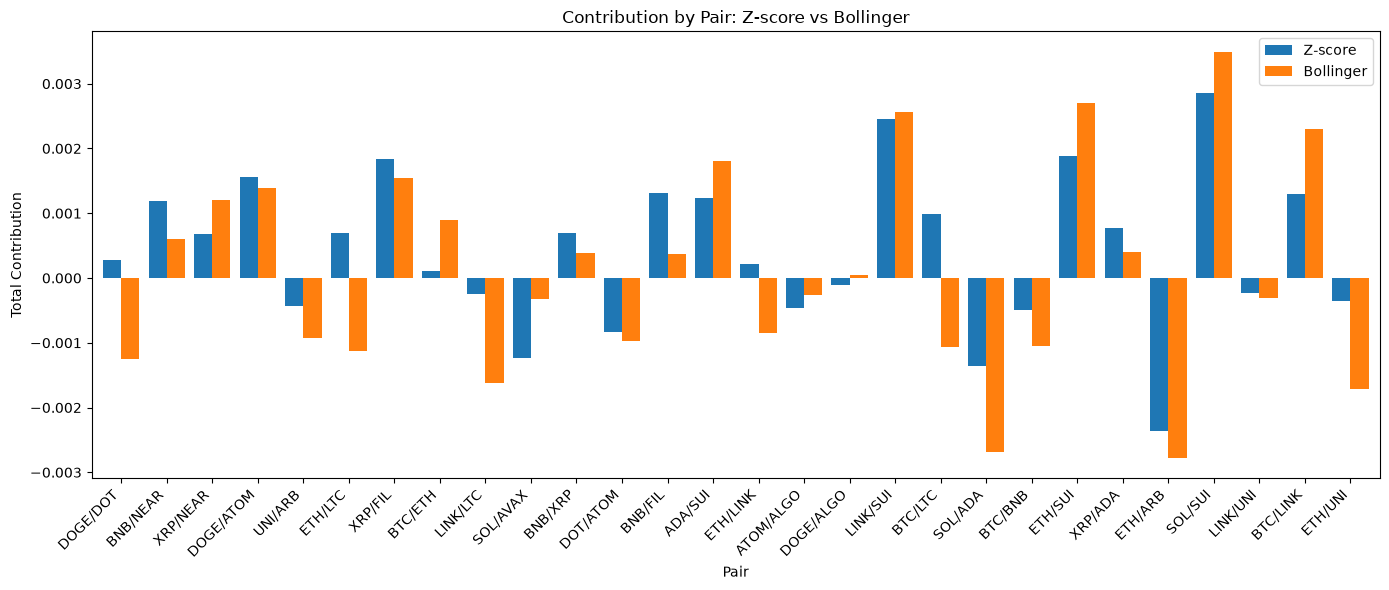

In [80]:
ax = pair_contrib_df.plot(kind="bar", figsize=(14, 6), width=0.8)
ax.set_title("Contribution by Pair: Z-score vs Bollinger")
ax.set_xlabel("Pair")
ax.set_ylabel("Total Contribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [81]:
# -----------------------------
# Helpers
# -----------------------------
ANN_FACTOR = np.sqrt(24 * 365)

def portfolio_metrics(port_ret: pd.Series) -> dict:
    """
    Compute standard portfolio metrics from a return series.
    """
    port_ret = port_ret.dropna()
    equity = (1 + port_ret.fillna(0)).cumprod()

    vol = port_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (port_ret.mean() / vol) * ANN_FACTOR
    max_dd = (equity / equity.cummax() - 1).min()

    return {
        "Sharpe": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) > 0 else np.nan,
        "Max Drawdown": max_dd,
        "Mean Hourly Return": port_ret.mean(),
        "Vol Hourly": vol,
        "N Obs": len(port_ret)
    }

def build_equal_vol_portfolio(strategy_name: str,
                              param_value: float,
                              fee_bps: float = 10.0,
                              exit_z: float = 0.25,
                              window: int = 25):
    """
    Re-run all selected pairs for one strategy and one parameter value,
    then combine pair return streams using equal-vol weighting.
    """
    pair_ret_series = []

    for _, row in selected_pairs.iterrows():
        a = row["Asset_A"]
        b = row["Asset_B"]

        if strategy_name == "zscore":
            bt, _ = backtest_pair_strategy(
                prices=prices,
                asset_a=a,
                asset_b=b,
                strategy="zscore",
                beta=row.get("Beta", None),
                window=window,
                entry_z=param_value,
                exit_z=exit_z,
                fee_bps=fee_bps
            )
        elif strategy_name == "bollinger":
            bt, _ = backtest_pair_strategy(
                prices=prices,
                asset_a=a,
                asset_b=b,
                strategy="bollinger",
                beta=row.get("Beta", None),
                window=window,
                band_k=param_value,
                fee_bps=fee_bps
            )
        else:
            raise ValueError("strategy_name must be 'zscore' or 'bollinger'")

        pair_name = f"{a}/{b}"
        pair_ret_series.append(bt["strategy_ret"].rename(pair_name))

    # Align all pair return series
    rets = pd.concat(pair_ret_series, axis=1, join="inner").dropna(how="any")

    # Equal-vol weights = inverse volatility, normalized to sum to 1
    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()

    # Portfolio return series
    port_ret = rets.mul(weights, axis=1).sum(axis=1)

    metrics = portfolio_metrics(port_ret)
    return port_ret, weights, metrics


,Strategy,Parameter,Sharpe,Cumulative Return,Max Drawdown,Mean Hourly Return,Vol Hourly,N Obs
0,Z-score,1.50,-4.255209,-0.014978,-0.019888,-2.085447e-05,0.000459,720
1,Z-score,2.00,-0.615095,-0.001945,-0.008573,-2.623778e-06,0.000399,720
2,Z-score,2.50,2.194574,0.005137,-0.005685,7.163030e-06,0.000305,720
3,Z-score,3.00,3.092234,0.004243,-0.003590,5.897155e-06,0.000178,720
4,Bollinger,0.75,-7.834581,-0.031137,-0.035300,-4.379551e-05,0.000523,720
5,Bollinger,1.00,-5.424727,-0.021425,-0.028184,-2.994711e-05,0.000517,720
6,Bollinger,1.25,-4.410514,-0.016856,-0.023449,-2.348621e-05,0.000498,720
7,Bollinger,1.50,-2.583882,-0.009472,-0.017214,-1.310631e-05,0.000475,720
8,Bollinger,2.00,0.209288,0.000613,-0.008023,9.395193e-07,0.000420,720


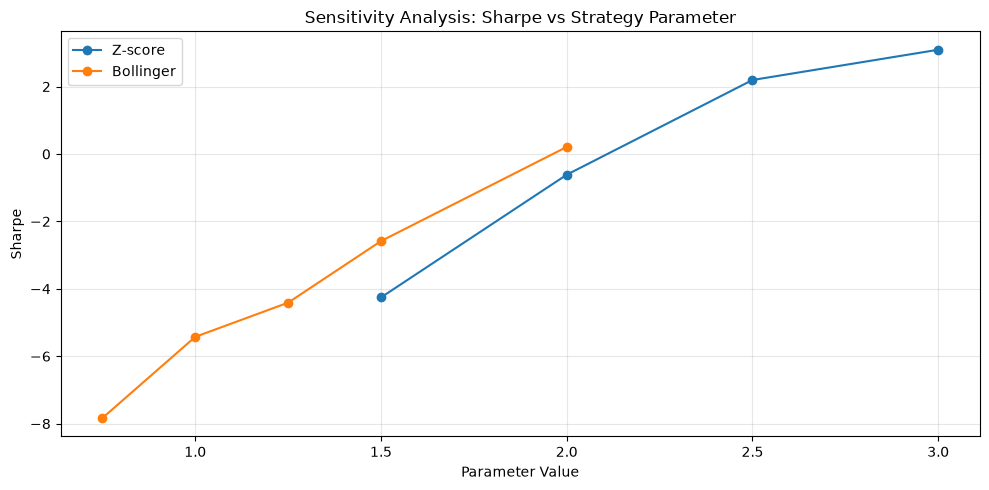

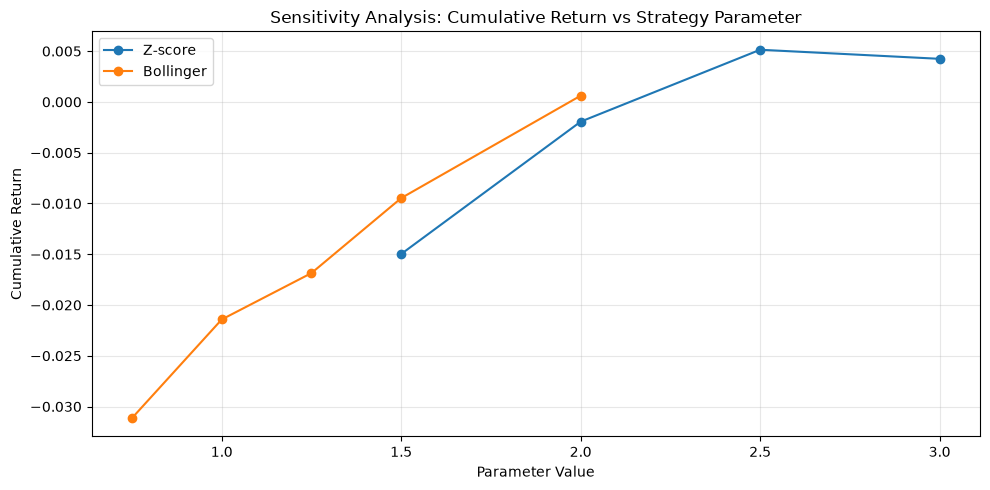

In [82]:
# ============================================================
# 1) PARAMETER SENSITIVITY
#    Z-score entry threshold and Bollinger band width
# ============================================================
z_entry_grid = [1.5, 2.0, 2.5, 3.0]
bb_k_grid = [0.75, 1.0, 1.25, 1.5, 2.0]

sens_rows = []
z_sens_returns = {}
bb_sens_returns = {}

# Z-score sensitivity
for x in z_entry_grid:
    port_ret, weights, metrics = build_equal_vol_portfolio(
        strategy_name="zscore",
        param_value=x,
        fee_bps=10.0,      # keep your current fee assumption here
        exit_z=0.25,
        window=25
    )
    sens_rows.append({
        "Strategy": "Z-score",
        "Parameter": x,
        **metrics
    })
    z_sens_returns[x] = port_ret

# Bollinger sensitivity
for k in bb_k_grid:
    port_ret, weights, metrics = build_equal_vol_portfolio(
        strategy_name="bollinger",
        param_value=k,
        fee_bps=10.0,
        window=25
    )
    sens_rows.append({
        "Strategy": "Bollinger",
        "Parameter": k,
        **metrics
    })
    bb_sens_returns[k] = port_ret

sens_df = pd.DataFrame(sens_rows)
display(sens_df)

# ---- Plot Sharpe sensitivity
plt.figure(figsize=(10, 5))

z_plot = sens_df[sens_df["Strategy"] == "Z-score"].sort_values("Parameter")
bb_plot = sens_df[sens_df["Strategy"] == "Bollinger"].sort_values("Parameter")

plt.plot(z_plot["Parameter"], z_plot["Sharpe"], marker="o", label="Z-score")
plt.plot(bb_plot["Parameter"], bb_plot["Sharpe"], marker="o", label="Bollinger")

plt.title("Sensitivity Analysis: Sharpe vs Strategy Parameter")
plt.xlabel("Parameter Value")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Plot cumulative return sensitivity
plt.figure(figsize=(10, 5))

plt.plot(z_plot["Parameter"], z_plot["Cumulative Return"], marker="o", label="Z-score")
plt.plot(bb_plot["Parameter"], bb_plot["Cumulative Return"], marker="o", label="Bollinger")

plt.title("Sensitivity Analysis: Cumulative Return vs Strategy Parameter")
plt.xlabel("Parameter Value")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Strategy,Fee_bps,Sharpe,Cumulative Return,Max Drawdown,Mean Hourly Return,Vol Hourly,N Obs
0,Z-score,0,14.157186,0.045136,-0.003851,0.000061,0.000406,720
1,Bollinger,0,14.735313,0.061237,-0.004209,0.000083,0.000525,720
2,Z-score,2,11.275289,0.035550,-0.003892,0.000049,0.000403,720
3,Bollinger,2,10.790616,0.044180,-0.004893,0.000060,0.000522,720
4,Z-score,5,6.866005,0.021333,-0.003961,0.000029,0.000401,720
5,Bollinger,5,4.764574,0.019089,-0.006798,0.000026,0.000519,720
6,Z-score,10,-0.615095,-0.001945,-0.008573,-0.000003,0.000399,720
7,Bollinger,10,-5.424727,-0.021425,-0.028184,-0.000030,0.000517,720
8,Z-score,15,-8.088275,-0.024728,-0.026506,-0.000035,0.000401,720
9,Bollinger,15,-15.542915,-0.060345,-0.060345,-0.000086,0.000520,720


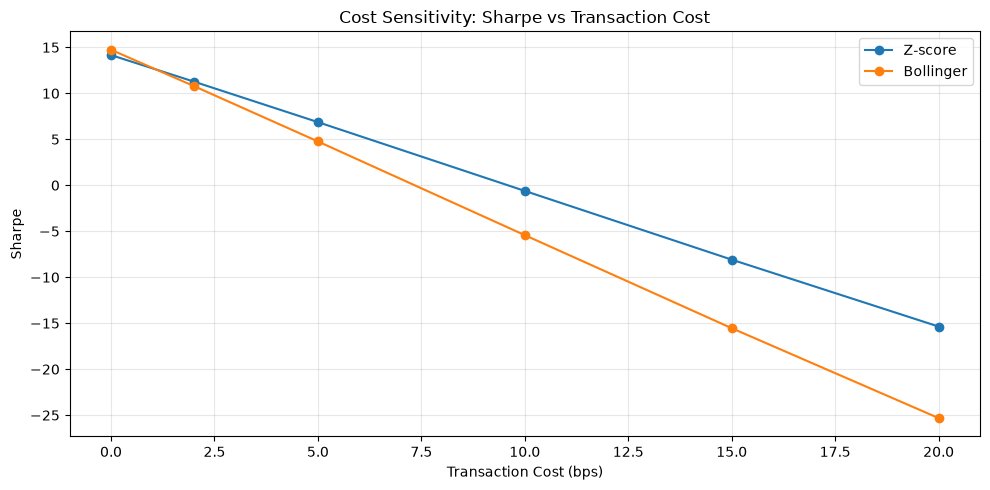

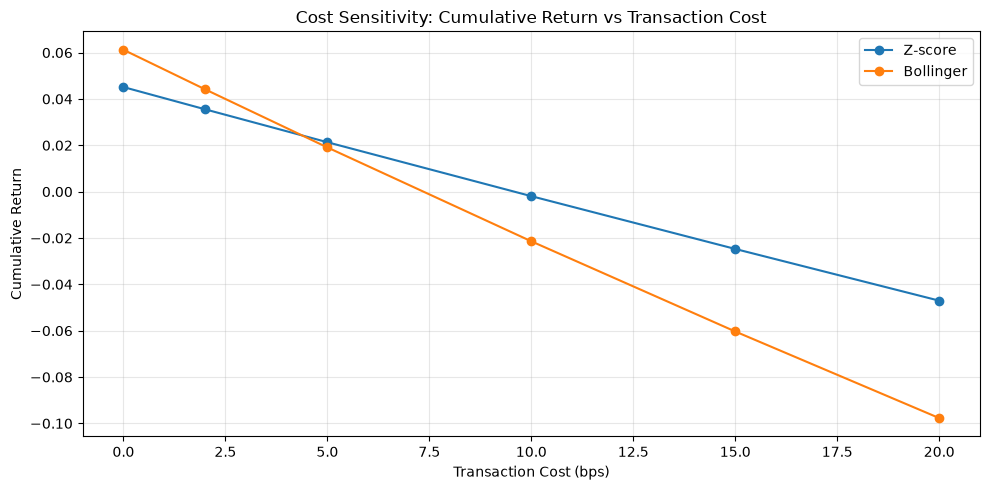

In [83]:
# ============================================================
# 2) COST SENSITIVITY
#    Re-run both portfolios under different transaction costs
# ============================================================
fee_grid = [0, 2, 5, 10, 15, 20]

cost_rows = []
z_cost_returns = {}
bb_cost_returns = {}

# Use your current strategy settings here
current_z_entry = 2.0
current_bb_k = 1.0

for fee in fee_grid:
    # Z-score portfolio at this fee
    z_ret, z_w, z_metrics = build_equal_vol_portfolio(
        strategy_name="zscore",
        param_value=current_z_entry,
        fee_bps=fee,
        exit_z=0.25,
        window=25
    )
    cost_rows.append({
        "Strategy": "Z-score",
        "Fee_bps": fee,
        **z_metrics
    })
    z_cost_returns[fee] = z_ret

    # Bollinger portfolio at this fee
    bb_ret, bb_w, bb_metrics = build_equal_vol_portfolio(
        strategy_name="bollinger",
        param_value=current_bb_k,
        fee_bps=fee,
        window=25
    )
    cost_rows.append({
        "Strategy": "Bollinger",
        "Fee_bps": fee,
        **bb_metrics
    })
    bb_cost_returns[fee] = bb_ret

cost_df = pd.DataFrame(cost_rows)
display(cost_df)

# ---- Plot Sharpe vs fees
plt.figure(figsize=(10, 5))

z_cost_plot = cost_df[cost_df["Strategy"] == "Z-score"].sort_values("Fee_bps")
bb_cost_plot = cost_df[cost_df["Strategy"] == "Bollinger"].sort_values("Fee_bps")

plt.plot(z_cost_plot["Fee_bps"], z_cost_plot["Sharpe"], marker="o", label="Z-score")
plt.plot(bb_cost_plot["Fee_bps"], bb_cost_plot["Sharpe"], marker="o", label="Bollinger")

plt.title("Cost Sensitivity: Sharpe vs Transaction Cost")
plt.xlabel("Transaction Cost (bps)")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Plot cumulative return vs fees
plt.figure(figsize=(10, 5))

plt.plot(z_cost_plot["Fee_bps"], z_cost_plot["Cumulative Return"], marker="o", label="Z-score")
plt.plot(bb_cost_plot["Fee_bps"], bb_cost_plot["Cumulative Return"], marker="o", label="Bollinger")

plt.title("Cost Sensitivity: Cumulative Return vs Transaction Cost")
plt.xlabel("Transaction Cost (bps)")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Project feedback:
The entire analysis uses only the latest 1,000 hourly observations, and the combined portfolio ultimately has only 720 observations -- approximately one month of data. This is much too short to support annualized Sharpe ratios or conclusions about which method performs better. I would ideally test several years of hourly data and reserve a substantial chronological period for out-of-sample validation.

The pair selection currently uses the full backtest period to estimate the regression beta, correlation, half-life and number of Z-score crossings. The same period is then used to trade the selected pairs. This creates selection bias. Select the pairs and estimate their hedge ratios using a training period, then hold those choices fixed when evaluating the test period. For a more realistic version, you could periodically reselect pairs and update betas using only trailing data.

The reported “P-value” is the significance of the OLS slope, not a cointegration test. Two nonstationary crypto prices can have a highly significant regression simply because both trend over time. Since this is a pairs-trading project, use the Engle–Granger cointegration test that you imported, or test the spread for stationarity with an ADF test, and report the relevant p-value.

The equal-volatility weights are calculated using volatility from the full return sample and then applied to that same sample. This introduces another forward-looking element. Estimate the weights on the training set or calculate them on a rolling basis using only past returns.

The results are extremely sensitive to costs. At 10 bps, the original Z-score specification has a negative Sharpe, and at 20 bps both approaches lose money substantially. Since the course assumption for crypto market orders is approximately 20 bps per dollar traded, the project should lead with the 20-bps results rather than the 7-bps results. Also report portfolio turnover so it is clear why the performance decays so quickly.

The portfolio contains many overlapping pairs, with the same coins appearing repeatedly. This means the 28 pair strategies are not necessarily 28 independent sources of diversification. It would be useful to aggregate the pair-level weights into net coin exposures and show whether the portfolio is concentrated in assets such as SUI, NEAR or DOGE.

After correcting the above, add benchmark-relative statistics for the portfolio: correlation and beta to BTC, annualized alpha and the alpha t-stat. I would also aggregate the hourly returns to daily returns before calculating the final Sharpe, which will make the annualization and interpretation cleaner.

Once you introduce a proper train/test structure, rolling hedge ratios and weights, and realistic 20-bps costs, the project will give a much more credible answer about whether either method has a robust edge.